# 06. XGBoost Classifier
In this notebook, we evaluate the **XGBoost Classifier** algorithm for hotel booking cancellation prediction.
- **Part 1:** Model without Hyperparameters (Default settings)
- **Part 2:** Model with Hyperparameters (Tuned settings)
- **Part 3:** Comparison between Default and Tuned versions

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve, average_precision_score, classification_report
)
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

# Paths
results_dir = f'../results/06_xgboost' if os.path.exists('../results') else f'results/06_xgboost'
models_dir = '../models' if os.path.exists('../models') else 'models'
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'

os.makedirs(results_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

# Load preprocessed data
X_train = pd.read_parquet(f'{data_dir}/X_train.parquet')
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_train = pd.read_csv(f'{data_dir}/y_train.csv').values.ravel()
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

print(f"Data Loaded: Train shape = {X_train.shape}, Test shape = {X_test.shape}")

Data Loaded: Train shape = (95366, 255), Test shape = (23842, 255)


## Part 1: Model Without Hyperparameters (Default Settings)
We train the model using standard default parameters.

Default Model Trained in 16.23 seconds
Accuracy:  0.8812
ROC-AUC:   0.9539
F1-Score:  0.8352
Precision: 0.8598
Recall:    0.8119


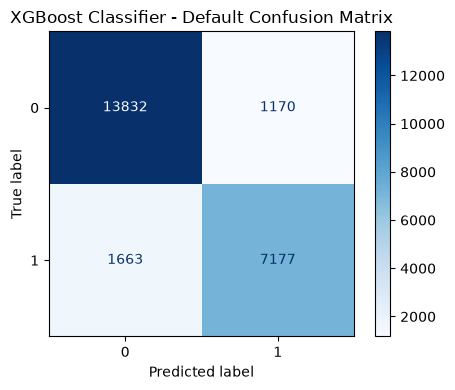

In [2]:
# Initialize and train default model
model_default = XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=-1)

start_time = time.time()
model_default.fit(X_train, y_train)
train_time_default = time.time() - start_time

# Evaluate on test data
y_prob_default = model_default.predict_proba(X_test)[:, 1]
y_pred_default = (y_prob_default >= 0.5).astype(int)

acc_default = accuracy_score(y_test, y_pred_default)
auc_default = roc_auc_score(y_test, y_prob_default)
f1_default = f1_score(y_test, y_pred_default)
prec_default = precision_score(y_test, y_pred_default)
rec_default = recall_score(y_test, y_pred_default)

print(f"Default Model Trained in {train_time_default:.2f} seconds")
print(f"Accuracy:  {acc_default:.4f}")
print(f"ROC-AUC:   {auc_default:.4f}")
print(f"F1-Score:  {f1_default:.4f}")
print(f"Precision: {prec_default:.4f}")
print(f"Recall:    {rec_default:.4f}")

# Save model
joblib.dump(model_default, f'{models_dir}/xgboost_default.joblib')

# Confusion matrix plot
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_default, ax=ax, cmap='Blues')
plt.title('XGBoost Classifier - Default Confusion Matrix')
plt.tight_layout()
plt.savefig(f'{results_dir}/confusion_matrix_default.png', dpi=300)
plt.show()

## Part 2: Model With Hyperparameters (Tuned Settings)
We use Cross-Validation to find better hyperparameter values and improve performance.

Tuning completed in 158.26 seconds
Best Parameters: {'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 150}
Tuned Model Test Accuracy:  0.8811
Tuned Model Test ROC-AUC:   0.9542
Tuned Model Test F1-Score:  0.8353


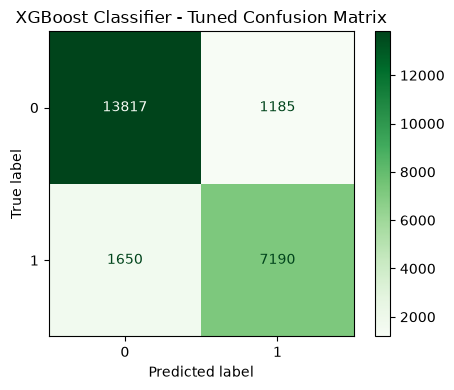

In [3]:
# Define hyperparameter search space
param_grid = {
    "n_estimators": [100, 150],
    "max_depth": [4, 6],
    "learning_rate": [0.1, 0.2]
}

start_tune = time.time()
grid_search = GridSearchCV(XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1), param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_
tune_time = time.time() - start_tune

print(f"Tuning completed in {tune_time:.2f} seconds")
print(f"Best Parameters: {best_params}")

# Evaluate tuned model on test set
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]
y_pred_tuned = (y_prob_tuned >= 0.5).astype(int)

acc_tuned = accuracy_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
prec_tuned = precision_score(y_test, y_pred_tuned)
rec_tuned = recall_score(y_test, y_pred_tuned)

print(f"Tuned Model Test Accuracy:  {acc_tuned:.4f}")
print(f"Tuned Model Test ROC-AUC:   {auc_tuned:.4f}")
print(f"Tuned Model Test F1-Score:  {f1_tuned:.4f}")

# Save tuned model
joblib.dump(best_model, f'{models_dir}/xgboost_tuned.joblib')

# Confusion matrix plot
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, ax=ax, cmap='Greens')
plt.title('XGBoost Classifier - Tuned Confusion Matrix')
plt.tight_layout()
plt.savefig(f'{results_dir}/confusion_matrix_tuned.png', dpi=300)
plt.show()

## Part 3: Direct Comparison (Default vs. Tuned)
We compare performance before and after tuning to see the exact improvement.

Performance Comparison Table:


,Metric,Default (No Tuning),Tuned,Improvement
0,Accuracy,0.881176,0.881092,-0.000084
1,ROC-AUC,0.953930,0.954236,0.000306
2,F1-Score,0.835166,0.835318,0.000152
3,Precision,0.859830,0.858507,-0.001322
4,Recall,0.811878,0.813348,0.001471
5,Specificity,0.922010,0.921011,-0.001000


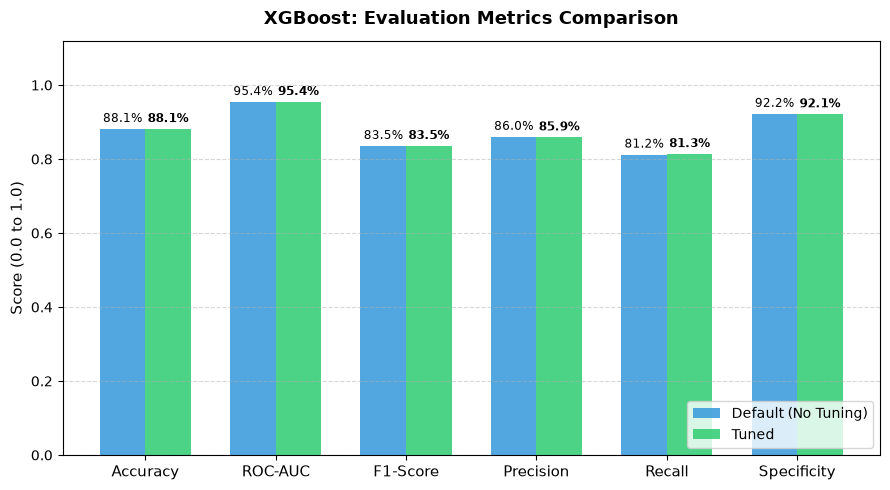

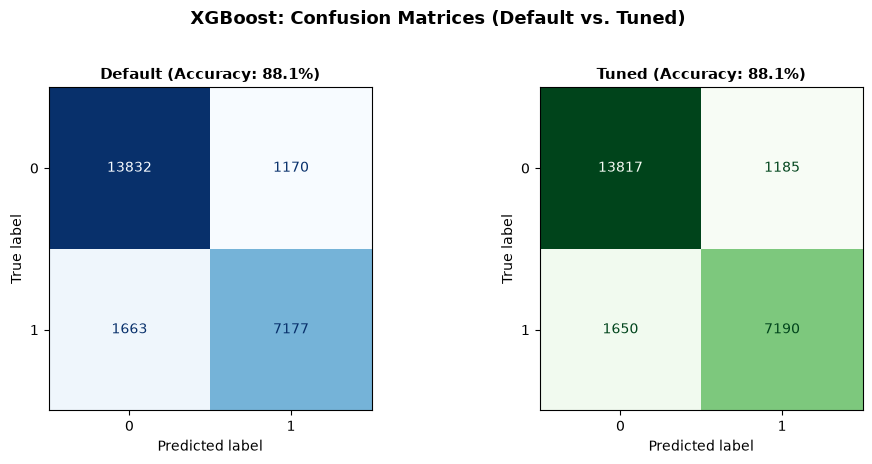

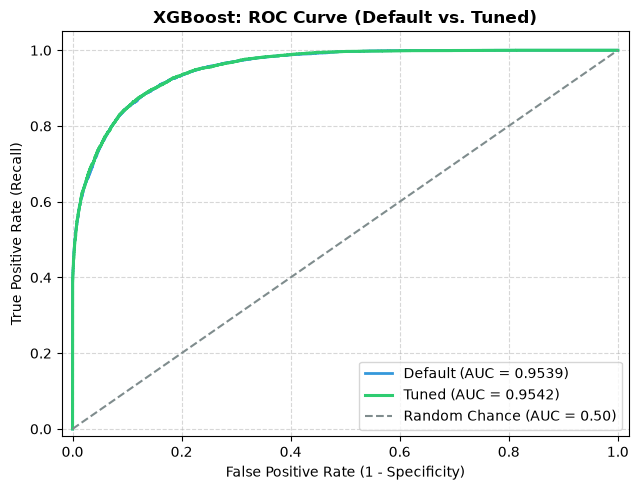

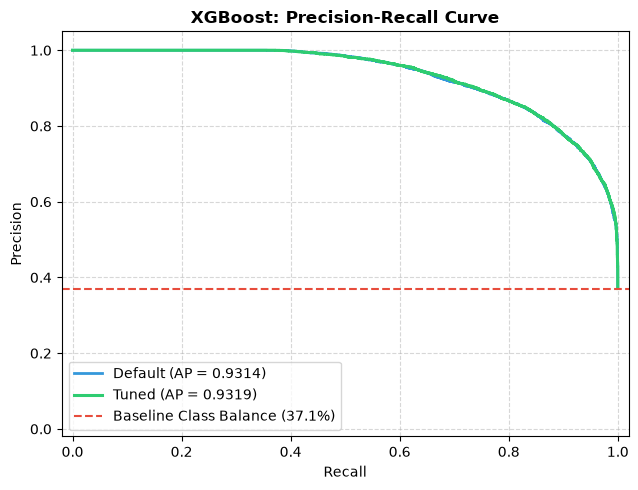

In [4]:
# Calculate Specificity (True Negative Rate)
tn_d, fp_d, fn_d, tp_d = confusion_matrix(y_test, y_pred_default).ravel()
spec_default = tn_d / (tn_d + fp_d)

tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, y_pred_tuned).ravel()
spec_tuned = tn_t / (tn_t + fp_t)

# Performance Comparison DataFrame with all evaluation metrics
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'ROC-AUC', 'F1-Score', 'Precision', 'Recall', 'Specificity'],
    'Default (No Tuning)': [acc_default, auc_default, f1_default, prec_default, rec_default, spec_default],
    'Tuned': [acc_tuned, auc_tuned, f1_tuned, prec_tuned, rec_tuned, spec_tuned]
})

comparison_df['Improvement'] = comparison_df['Tuned'] - comparison_df['Default (No Tuning)']
comparison_df.to_csv(f'{results_dir}/metrics_comparison.csv', index=False)

print("Performance Comparison Table:")
display(comparison_df)

# 1. Bar Chart: All Evaluation Metrics Comparison
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(comparison_df))
width = 0.35
rects1 = ax.bar(x - width/2, comparison_df['Default (No Tuning)'], width, label='Default (No Tuning)', color='#3498db', alpha=0.85)
rects2 = ax.bar(x + width/2, comparison_df['Tuned'], width, label='Tuned', color='#2ecc71', alpha=0.85)

ax.set_title('XGBoost: Evaluation Metrics Comparison', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Score (0.0 to 1.0)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=11)
ax.set_ylim(0, 1.12)
ax.legend(loc='lower right', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Value annotations on bars
for bar in rects1:
    h = bar.get_height()
    ax.annotate(f'{h*100:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
for bar in rects2:
    h = bar.get_height()
    ax.annotate(f'{h*100:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{results_dir}/metrics_comparison.png', dpi=300)
plt.savefig(f'{results_dir}/comparison_barchart.png', dpi=300)
plt.show()

# 2. Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_default, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Default (Accuracy: {acc_default*100:.1f}%)', fontsize=11, fontweight='bold')
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f'Tuned (Accuracy: {acc_tuned*100:.1f}%)', fontsize=11, fontweight='bold')
axes[1].grid(False)

plt.suptitle('XGBoost: Confusion Matrices (Default vs. Tuned)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{results_dir}/confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. ROC Curve Comparison
fpr_d, tpr_d, _ = roc_curve(y_test, y_prob_default)
fpr_t, tpr_t, _ = roc_curve(y_test, y_prob_tuned)

plt.figure(figsize=(6.5, 5))
plt.plot(fpr_d, tpr_d, color='#3498db', lw=2, label=f'Default (AUC = {auc_default:.4f})')
plt.plot(fpr_t, tpr_t, color='#2ecc71', lw=2.2, label=f'Tuned (AUC = {auc_tuned:.4f})')
plt.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', lw=1.5, label='Random Chance (AUC = 0.50)')
plt.title('XGBoost: ROC Curve (Default vs. Tuned)', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=10)
plt.ylabel('True Positive Rate (Recall)', fontsize=10)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.05])
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{results_dir}/roc_curve.png', dpi=300)
plt.show()

# 4. Precision-Recall Curve Comparison
prec_curve_d, rec_curve_d, _ = precision_recall_curve(y_test, y_prob_default)
prec_curve_t, rec_curve_t, _ = precision_recall_curve(y_test, y_prob_tuned)
ap_d = average_precision_score(y_test, y_prob_default)
ap_t = average_precision_score(y_test, y_prob_tuned)
prevalence = y_test.mean()

plt.figure(figsize=(6.5, 5))
plt.plot(rec_curve_d, prec_curve_d, color='#3498db', lw=2, label=f'Default (AP = {ap_d:.4f})')
plt.plot(rec_curve_t, prec_curve_t, color='#2ecc71', lw=2.2, label=f'Tuned (AP = {ap_t:.4f})')
plt.axhline(prevalence, color='#e74c3c', linestyle='--', lw=1.5, label=f'Baseline Class Balance ({prevalence*100:.1f}%)')
plt.title('XGBoost: Precision-Recall Curve', fontsize=12, fontweight='bold')
plt.xlabel('Recall', fontsize=10)
plt.ylabel('Precision', fontsize=10)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.05])
plt.legend(loc='lower left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{results_dir}/precision_recall_curve.png', dpi=300)
plt.show()
